# Movie Recommendation System

**Dataset:** MovieLens 100K (943 users, 1,682 movies, 100,000 ratings from 1 to 5)

**Goal:** recommend top-rated *unseen* movies to a user based on user similarity, and evaluate with **Precision@K**.

**Bonus:** item-based collaborative filtering and matrix factorization (SVD).

**Plan**
1. Load and explore the data
2. Train / validation / test split (per user)
3. Build the user-item matrix
4. User-based collaborative filtering (cosine similarity)
5. Evaluation with Precision@K
6. item-based CF
7. SVD matrix factorization
8. Compare all models and show example recommendations

## 1. Imports and data loading

In [1]:
import os, io, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse.linalg import svds
from sklearn.metrics.pairwise import cosine_similarity

SEED = 42
rng = np.random.default_rng(SEED)
pd.set_option("display.max_colwidth", 60)

The loader below looks for `u.data` / `u.item` in common places (current folder, `ml-100k/`, the Kaggle input folder).
If it can't find them, it downloads the official zip from GroupLens.
If you downloaded the Kaggle version, just put the `ml-100k` folder next to this notebook.

In [2]:
CANDIDATE_DIRS = [
    ".", "ml-100k", "data/ml-100k", "data",
    "/kaggle/input/movielens-100k-dataset/ml-100k",
    "/kaggle/input/movielens-100k-dataset",
    "/content/ml-100k",
]

def find_data_dir():
    for d in CANDIDATE_DIRS:
        if os.path.exists(os.path.join(d, "u.data")) and os.path.exists(os.path.join(d, "u.item")):
            return d
    return None

data_dir = find_data_dir()
if data_dir is None:
    url = "https://files.grouplens.org/datasets/movielens/ml-100k.zip"
    print("Downloading MovieLens 100K from GroupLens ...")
    with urllib.request.urlopen(url) as r:
        zipfile.ZipFile(io.BytesIO(r.read())).extractall(".")
    data_dir = "ml-100k"

print("Using data from:", os.path.abspath(data_dir))

ratings = pd.read_csv(
    os.path.join(data_dir, "u.data"), sep="\t",
    names=["user_id", "item_id", "rating", "timestamp"],
)
movies = pd.read_csv(
    os.path.join(data_dir, "u.item"), sep="|", encoding="latin-1",
    usecols=[0, 1], names=["item_id", "title"],
)
ratings.head()

Using data from: /content/ml-100k


,user_id,item_id,rating,timestamp
0,196,242,3,881250949
1,186,302,3,891717742
2,22,377,1,878887116
3,244,51,2,880606923
4,166,346,1,886397596


## 2. Quick exploration

Ratings: 100,000 | Users: 943 | Movies: 1682
Matrix sparsity: 93.70%
Min ratings per user: 20


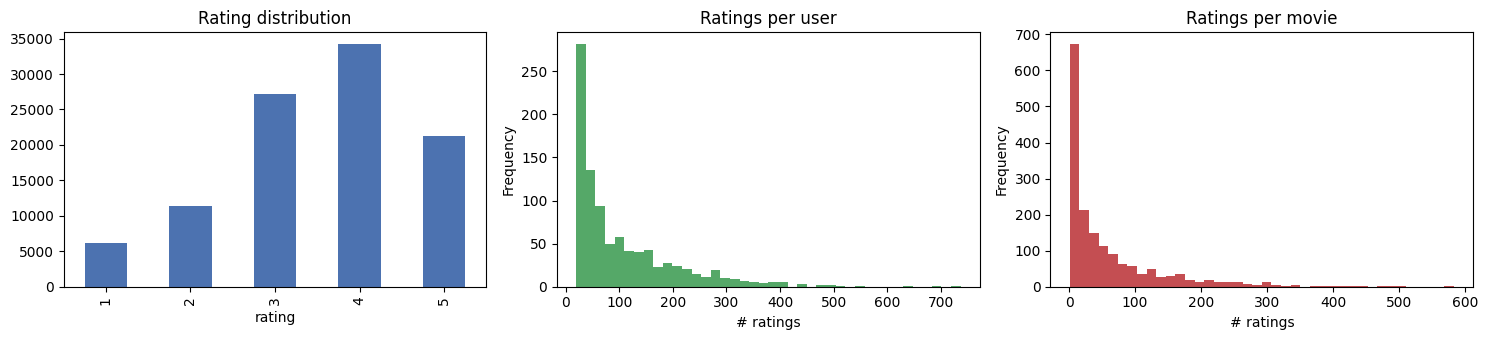

In [3]:
n_users, n_items = ratings.user_id.nunique(), ratings.item_id.nunique()
sparsity = 1 - len(ratings) / (n_users * n_items)
print(f"Ratings: {len(ratings):,} | Users: {n_users} | Movies: {n_items}")
print(f"Matrix sparsity: {sparsity:.2%}")
print(f"Min ratings per user: {ratings.groupby('user_id').size().min()}")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
ratings.rating.value_counts().sort_index().plot.bar(ax=ax[0], color="#4C72B0")
ax[0].set_title("Rating distribution"); ax[0].set_xlabel("rating")
ratings.groupby("user_id").size().plot.hist(bins=40, ax=ax[1], color="#55A868")
ax[1].set_title("Ratings per user"); ax[1].set_xlabel("# ratings")
ratings.groupby("item_id").size().plot.hist(bins=40, ax=ax[2], color="#C44E52")
ax[2].set_title("Ratings per movie"); ax[2].set_xlabel("# ratings")
plt.tight_layout(); plt.show()

The matrix is about 94% empty, so most user/movie pairs are unknown. That is what the recommender has to fill in.

## 3. Train / validation / test split

For each user we hold out a random 20% of their ratings as the **test** set.
From the remaining ratings, another 10% per user is held out as a **validation** set, which we use only for tuning hyperparameters (number of neighbours, number of SVD factors).
This keeps the test set clean.

A held-out movie counts as **relevant** if the user rated it **≥ 4**.

In [4]:
RELEVANT_THRESHOLD = 4

def split_per_user(df, frac, seed):
    rs = np.random.RandomState(seed)
    test_idx = []
    for _, g in df.groupby("user_id"):
        n = max(1, int(round(len(g) * frac)))
        test_idx.extend(rs.choice(g.index.values, size=n, replace=False))
    test = df.loc[test_idx]
    train = df.drop(test.index)
    return train.reset_index(drop=True), test.reset_index(drop=True)

train_full, test = split_per_user(ratings, 0.20, SEED)
train_sub, val = split_per_user(train_full, 0.10, SEED + 1)

print(f"train_full: {len(train_full):,} | test: {len(test):,}")
print(f"train_sub:  {len(train_sub):,} | val:  {len(val):,}")

train_full: 80,000 | test: 20,000
train_sub:  71,981 | val:  8,019


## 4. User-item matrix

Rows are users, columns are movies, values are ratings (0 = not rated).
We also keep a binary **mask** of observed entries and a **mean-centered** version (each user's average is subtracted from their ratings), which corrects for users who rate generously or harshly.

In [5]:
user_ids = np.sort(ratings.user_id.unique())
item_ids = np.sort(ratings.item_id.unique())
u_index = {u: i for i, u in enumerate(user_ids)}
i_index = {m: j for j, m in enumerate(item_ids)}

def build_matrix(df):
    R = np.zeros((len(user_ids), len(item_ids)), dtype=np.float64)
    rows = df.user_id.map(u_index).values
    cols = df.item_id.map(i_index).values
    R[rows, cols] = df.rating.values
    return R

def center(R):
    mask = (R > 0).astype(np.float64)
    counts = mask.sum(1)
    user_mean = np.divide(R.sum(1), counts, out=np.full(R.shape[0], R[R > 0].mean()), where=counts > 0)
    Rc = (R - user_mean[:, None]) * mask
    return Rc, mask, user_mean

R_full = build_matrix(train_full)
user_item = pd.DataFrame(R_full, index=user_ids, columns=item_ids)
user_item.iloc[:5, :8]

,1,2,3,4,5,6,7,8
1,5.0,0.0,4.0,0.0,3.0,5.0,4.0,1.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,4.0,3.0,0.0,0.0,0.0,0.0,0.0,0.0


## 5. Evaluation: Precision@K

For every user we:
1. score all movies the user has **not** seen in the training data,
2. take the top **K** by score,
3. check how many of them appear in the user's held-out **relevant** items (rating ≥ 4).

**Precision@K** = (relevant items in the top K) / K, averaged over users who have at least one relevant held-out item.
I also report **Recall@K** for context.

In [6]:
def evaluate(scores, R_train, held_out, ks=(5, 10, 20), threshold=RELEVANT_THRESHOLD):
    """scores: (n_users, n_items) predicted scores. R_train: matrix used for fitting (seen items are excluded)."""
    s = scores.copy()
    s[R_train > 0] = -np.inf                       # never recommend already-seen movies
    max_k = max(ks)
    top = np.argpartition(-s, max_k, axis=1)[:, :max_k]
    order = np.take_along_axis(s, top, axis=1).argsort(axis=1)[:, ::-1]
    top = np.take_along_axis(top, order, axis=1)   # sorted top-max_k item indices per user

    rel = held_out[held_out.rating >= threshold]
    rel_sets = rel.groupby("user_id").item_id.apply(lambda x: {i_index[i] for i in x}).to_dict()

    out = {f"P@{k}": [] for k in ks} | {f"R@{k}": [] for k in ks}
    for u, relevant in rel_sets.items():
        recs = top[u_index[u]]
        for k in ks:
            hits = len(set(recs[:k]) & relevant)
            out[f"P@{k}"].append(hits / k)
            out[f"R@{k}"].append(hits / len(relevant))
    return {m: float(np.mean(v)) for m, v in out.items()}

### Baseline: popularity

A sanity check. Recommend the movies with the best *damped* average rating (movies with few ratings are pulled toward the global mean), the same for every user.
Any personalized model should beat this.

In [7]:
def popularity_scores(R, damping=10):
    mask = R > 0
    counts = mask.sum(0)
    global_mean = R[mask].mean()
    item_mean = (R.sum(0) + damping * global_mean) / (counts + damping)
    return np.tile(item_mean, (R.shape[0], 1))

pop_val = evaluate(popularity_scores(build_matrix(train_sub)), build_matrix(train_sub), val)
pop_val

{'P@5': 0.028312570781426953,
 'P@10': 0.027633069082672705,
 'P@20': 0.025877689694224236,
 'R@5': 0.025613885822443023,
 'R@10': 0.04938179001368589,
 'R@20': 0.09447373553994298}

## 6. User-based collaborative filtering

**Idea:** users who rated movies similarly will probably like similar movies.

1. Compute **cosine similarity** between every pair of users on their mean-centered rating vectors (this is the same as Pearson correlation over co-rated items, roughly).
2. For each user keep only the **k most similar neighbours**.
3. Predict a rating for an unseen movie as the user's average plus the similarity-weighted average of how neighbours' ratings deviate from *their own* averages:

$$\hat r_{u,i} = \bar r_u + \frac{\sum_{v \in N_k(u)} \text{sim}(u,v)\,(r_{v,i}-\bar r_v)}{\sum_{v \in N_k(u)} |\text{sim}(u,v)| \;+\; \lambda}$$

where the damping term $\lambda$ stops movies rated by only one similar neighbour from getting extreme scores.
4. Recommend the unseen movies with the highest predicted rating.

In [8]:
def keep_top_k(S, k):
    """Zero out everything except the k largest values in each row."""
    out = np.zeros_like(S)
    idx = np.argpartition(-S, k, axis=1)[:, :k]
    rows = np.arange(S.shape[0])[:, None]
    out[rows, idx] = S[rows, idx]
    return out

def user_based_scores(R, k=50, damping=5.0):
    Rc, mask, user_mean = center(R)
    S = cosine_similarity(Rc)
    np.fill_diagonal(S, 0)                      # a user is not their own neighbour
    S = keep_top_k(S, k)
    num = S @ Rc
    den = np.abs(S) @ mask
    return user_mean[:, None] + num / (den + damping)

# Tune the number of neighbours on the validation split
R_sub = build_matrix(train_sub)
rows = []
for k in [10, 20, 30, 50, 100, 200]:
    m = evaluate(user_based_scores(R_sub, k=k), R_sub, val)
    rows.append({"k_neighbors": k, **m})
ub_tuning = pd.DataFrame(rows).set_index("k_neighbors")
ub_tuning.round(4)

,P@5,P@10,P@20,R@5,R@10,R@20
k_neighbors,,,,,,
10,0.0627,0.0535,0.0418,0.0705,0.1244,0.1840
20,0.0734,0.0586,0.0462,0.0921,0.1368,0.2040
30,0.0761,0.0613,0.0468,0.0939,0.1485,0.2128
50,0.0757,0.0640,0.0492,0.0899,0.1489,0.2156
100,0.0777,0.0610,0.0481,0.0939,0.1402,0.2110
200,0.0729,0.0562,0.0451,0.0877,0.1240,0.1904


Best number of neighbours (by validation P@10): 50


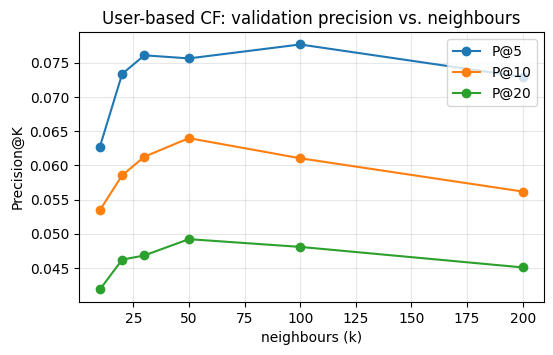

In [9]:
best_k_user = ub_tuning["P@10"].idxmax()
print("Best number of neighbours (by validation P@10):", best_k_user)
ub_tuning[["P@5", "P@10", "P@20"]].plot(marker="o", figsize=(6, 3.5), title="User-based CF: validation precision vs. neighbours")
plt.xlabel("neighbours (k)"); plt.ylabel("Precision@K"); plt.grid(alpha=.3); plt.show()

### Recommendations for a specific user

`recommend_for_user` returns the top-N unseen movies with their predicted ratings.

In [10]:
def recommend_for_user(user_id, scores, R_train, n=10):
    u = u_index[user_id]
    s = scores[u].copy()
    s[R_train[u] > 0] = -np.inf
    top = np.argsort(-s)[:n]
    return pd.DataFrame({
        "item_id": item_ids[top],
        "title": movies.set_index("item_id").loc[item_ids[top], "title"].values,
        "predicted_rating": np.clip(s[top], 1, 5).round(2),
    }).reset_index(drop=True)

# fit final user-based model on the full training set
ub_scores = user_based_scores(R_full, k=best_k_user)

demo_user = 196
print(f"Movies user {demo_user} already rated highly (>=4), a sample:")
seen = train_full[(train_full.user_id == demo_user) & (train_full.rating >= 4)].merge(movies, on="item_id")
display(seen[["title", "rating"]].head(8))

print(f"Top-10 recommendations for user {demo_user} (user-based CF):")
recommend_for_user(demo_user, ub_scores, R_full, n=10)

Movies user 196 already rated highly (>=4), a sample:


,title,rating
0,Mrs. Doubtfire (1993),4
1,Stand by Me (1986),5
2,Ace Ventura: Pet Detective (1994),5
3,"Mrs. Brown (Her Majesty, Mrs. Brown) (1997)",4
4,"Truth About Cats & Dogs, The (1996)",4
5,"Birdcage, The (1996)",4
6,"American President, The (1995)",5
7,Harold and Maude (1971),4


Top-10 recommendations for user 196 (user-based CF):


,item_id,title,predicted_rating
0,64,"Shawshank Redemption, The (1994)",3.74
1,50,Star Wars (1977),3.73
2,357,One Flew Over the Cuckoo's Nest (1975),3.72
3,98,"Silence of the Lambs, The (1991)",3.70
4,191,Amadeus (1984),3.70
5,127,"Godfather, The (1972)",3.69
6,435,Butch Cassidy and the Sundance Kid (1969),3.69
7,427,To Kill a Mockingbird (1962),3.67
8,318,Schindler's List (1993),3.66
9,194,"Sting, The (1973)",3.65


## 7. item-based collaborative filtering

**Idea:** instead of finding similar users, find similar *movies*. If you liked movie A and movie B is rated similarly to A by everyone, you will probably like B.

We use **adjusted cosine similarity** (cosine on user-mean-centered ratings), the standard choice for item-based CF.
A user's predicted rating for movie *i* is their average plus the similarity-weighted average of their deviations on the *k* most similar movies they have rated:

$$\hat r_{u,i} = \bar r_u + \frac{\sum_{j \in N_k(i)} \text{sim}(i,j)\,(r_{u,j}-\bar r_u)}{\sum_{j \in N_k(i)} |\text{sim}(i,j)| \cdot \mathbb{1}[u \text{ rated } j] \;+\; \lambda}$$

Item-based CF is often more stable than user-based because item similarities change slowly, and it tends to explain recommendations well ("because you liked X").

In [11]:
def item_based_scores(R, k=30, damping=5.0, min_common=3):
    Rc, mask, user_mean = center(R)
    S = cosine_similarity(Rc.T)                 # item-item similarity
    np.fill_diagonal(S, 0)
    # ignore similarities backed by very few common raters (they are mostly noise)
    common = mask.T @ mask
    S[common < min_common] = 0
    S = keep_top_k(S, k)
    num = Rc @ S.T
    den = mask @ np.abs(S).T
    return user_mean[:, None] + num / (den + damping)

rows = []
for k in [10, 20, 30, 50, 100, 200]:
    m = evaluate(item_based_scores(R_sub, k=k), R_sub, val)
    rows.append({"k_neighbors": k, **m})
ib_tuning = pd.DataFrame(rows).set_index("k_neighbors")
best_k_item = ib_tuning["P@10"].idxmax()
print("Best number of similar items (by validation P@10):", best_k_item)
ib_tuning.round(4)

Best number of similar items (by validation P@10): 30


,P@5,P@10,P@20,R@5,R@10,R@20
k_neighbors,,,,,,
10,0.0650,0.0532,0.0425,0.0749,0.1127,0.1735
20,0.0682,0.0549,0.0432,0.0766,0.1171,0.1742
30,0.0670,0.0555,0.0429,0.0752,0.1157,0.1730
50,0.0693,0.0547,0.0421,0.0793,0.1184,0.1754
100,0.0695,0.0533,0.0404,0.0835,0.1161,0.1663
200,0.0614,0.0485,0.0384,0.0712,0.1042,0.1586


In [12]:
ib_scores = item_based_scores(R_full, k=best_k_item)
print(f"Top-10 recommendations for user {demo_user} (item-based CF):")
recommend_for_user(demo_user, ib_scores, R_full, n=10)

Top-10 recommendations for user 196 (item-based CF):


,item_id,title,predicted_rating
0,232,Young Guns (1988),3.67
1,1063,"Little Princess, A (1995)",3.66
2,356,"Client, The (1994)",3.65
3,209,This Is Spinal Tap (1984),3.64
4,468,Rudy (1993),3.63
5,28,Apollo 13 (1995),3.63
6,856,Night on Earth (1991),3.63
7,651,Glory (1989),3.63
8,954,Unzipped (1995),3.62
9,317,In the Name of the Father (1993),3.62


In [13]:
Rc_full, mask_full, _ = center(R_full)
S_item = cosine_similarity(Rc_full.T)
common_full = mask_full.T @ mask_full

def similar_movies(title_substr, n=8, min_common=20):
    match = movies[movies.title.str.contains(title_substr, case=False, regex=False)]
    if match.empty:
        return f"No movie matching '{title_substr}'"
    j = i_index[match.iloc[0].item_id]
    s = S_item[j].copy()
    s[common_full[j] < min_common] = -np.inf
    s[j] = -np.inf
    top = np.argsort(-s)[:n]
    print("Movies most similar to:", match.iloc[0].title)
    return pd.DataFrame({"title": movies.set_index("item_id").loc[item_ids[top], "title"].values,
                         "similarity": s[top].round(3)})

similar_movies("Toy Story")

Movies most similar to: Toy Story (1995)


,title,similarity
0,Star Wars (1977),0.228
1,"Empire Strikes Back, The (1980)",0.210
2,Raiders of the Lost Ark (1981),0.200
3,Beauty and the Beast (1991),0.194
4,"Close Shave, A (1995)",0.193
5,Aladdin (1992),0.189
6,Return of the Jedi (1983),0.184
7,Apollo 13 (1995),0.180


## 8. Matrix factorization with SVD

**Idea:** compress the huge sparse matrix into a small number of **latent factors** (think "taste dimensions" such as action vs. romance, or old vs. new).
Each user and each movie gets a short vector, and the predicted rating is their dot product.

We mean-center the matrix (missing entries become 0, i.e. "average for this user"), then take a truncated SVD:

$$R_c \approx U_k \Sigma_k V_k^\top \qquad \hat r_{u,i} = \bar r_u + (U_k \Sigma_k V_k^\top)_{u,i}$$

The number of factors *k* controls the trade-off: too few underfit, too many overfit the noise in the sparse data.

In [14]:
def svd_scores(R, k=20):
    Rc, mask, user_mean = center(R)
    U, sigma, Vt = svds(Rc, k=k)
    return user_mean[:, None] + (U * sigma) @ Vt

rows = []
for k in [5, 10, 15, 20, 30, 50]:
    m = evaluate(svd_scores(R_sub, k=k), R_sub, val)
    rows.append({"n_factors": k, **m})
svd_tuning = pd.DataFrame(rows).set_index("n_factors")
best_k_svd = svd_tuning["P@10"].idxmax()
print("Best number of factors (by validation P@10):", best_k_svd)
svd_tuning.round(4)

Best number of factors (by validation P@10): 10


,P@5,P@10,P@20,R@5,R@10,R@20
n_factors,,,,,,
5,0.0691,0.0538,0.0448,0.0737,0.1064,0.1629
10,0.0784,0.0624,0.0473,0.0943,0.1372,0.1938
15,0.0768,0.0591,0.0468,0.0890,0.1300,0.1940
20,0.0745,0.0591,0.0454,0.0937,0.1335,0.1863
30,0.0709,0.0555,0.0444,0.0854,0.1234,0.1920
50,0.0564,0.0472,0.0369,0.0715,0.1112,0.1584


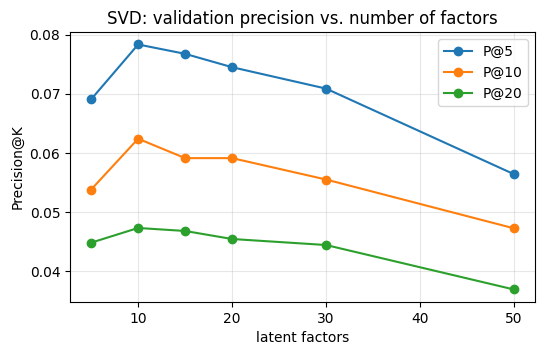

Top-10 recommendations for user 196 (SVD):


,item_id,title,predicted_rating
0,260,Event Horizon (1997),3.64
1,100,Fargo (1996),3.63
2,185,Psycho (1960),3.63
3,288,Scream (1996),3.63
4,197,"Graduate, The (1967)",3.61
5,23,Taxi Driver (1976),3.61
6,219,"Nightmare on Elm Street, A (1984)",3.61
7,427,To Kill a Mockingbird (1962),3.61
8,276,Leaving Las Vegas (1995),3.61
9,472,Dragonheart (1996),3.60


In [15]:
svd_tuning[["P@5", "P@10", "P@20"]].plot(marker="o", figsize=(6, 3.5), title="SVD: validation precision vs. number of factors")
plt.xlabel("latent factors"); plt.ylabel("Precision@K"); plt.grid(alpha=.3); plt.show()

svd_final = svd_scores(R_full, k=best_k_svd)
print(f"Top-10 recommendations for user {demo_user} (SVD):")
recommend_for_user(demo_user, svd_final, R_full, n=10)

## 9. Final comparison on the test set

All models are fitted on `train_full` (everything except the test split) using the hyperparameters chosen on the validation set.

In [16]:
results = {
    "Popularity (baseline)": evaluate(popularity_scores(R_full), R_full, test),
    f"User-based CF (k={best_k_user})": evaluate(ub_scores, R_full, test),
    f"Item-based CF (k={best_k_item})": evaluate(ib_scores, R_full, test),
    f"SVD ({best_k_svd} factors)": evaluate(svd_final, R_full, test),
}
results_df = pd.DataFrame(results).T
results_df.round(4)

,P@5,P@10,P@20,R@5,R@10,R@20
Popularity (baseline),0.0732,0.0733,0.0675,0.0257,0.0534,0.1019
User-based CF (k=50),0.2112,0.1723,0.1325,0.1051,0.1694,0.2482
Item-based CF (k=30),0.1959,0.1562,0.1194,0.0963,0.1470,0.2161
SVD (10 factors),0.2099,0.1700,0.1319,0.0977,0.1504,0.2286


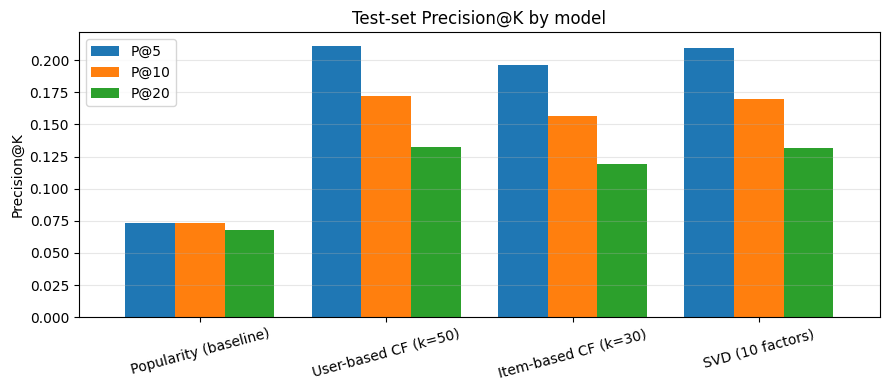

In [17]:
ax = results_df[["P@5", "P@10", "P@20"]].plot.bar(figsize=(9, 4), rot=15, width=0.8)
ax.set_ylabel("Precision@K"); ax.set_title("Test-set Precision@K by model")
ax.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.show()

## 10. Side-by-side recommendations

Same user, three models. You can change `demo_user` to any id from 1 to 943.

In [18]:
side = pd.concat({
    "User-based": recommend_for_user(demo_user, ub_scores, R_full, 10).title,
    "Item-based": recommend_for_user(demo_user, ib_scores, R_full, 10).title,
    "SVD": recommend_for_user(demo_user, svd_final, R_full, 10).title,
}, axis=1)
side.index = side.index + 1
side

,User-based,Item-based,SVD
1,"Shawshank Redemption, The (1994)",Young Guns (1988),Event Horizon (1997)
2,Star Wars (1977),"Little Princess, A (1995)",Fargo (1996)
3,One Flew Over the Cuckoo's Nest (1975),"Client, The (1994)",Psycho (1960)
4,"Silence of the Lambs, The (1991)",This Is Spinal Tap (1984),Scream (1996)
5,Amadeus (1984),Rudy (1993),"Graduate, The (1967)"
6,"Godfather, The (1972)",Apollo 13 (1995),Taxi Driver (1976)
7,Butch Cassidy and the Sundance Kid (1969),Night on Earth (1991),"Nightmare on Elm Street, A (1984)"
8,To Kill a Mockingbird (1962),Glory (1989),To Kill a Mockingbird (1962)
9,Schindler's List (1993),Unzipped (1995),Leaving Las Vegas (1995)
10,"Sting, The (1973)",In the Name of the Father (1993),Dragonheart (1996)


## Conclusions

* A **user-item matrix** built from the ratings gives us everything we need: user similarity (cosine on mean-centered rows), item similarity (cosine on columns) and the low-rank factorization.
* Recommendations are always the **top-scored unseen** movies; already-rated titles are masked before ranking.
* **Precision@K** is evaluated on held-out ratings ≥ 4. Every personalized model should beat the popularity baseline; check the table above for the exact numbers on your run.
* **Hyperparameters** (neighbours, factors) were chosen on a validation split so the test numbers are not tuned on the test data.
* Precision@K values on MovieLens look low in absolute terms because only about 20% of each user's ratings are held out, so most good movies a user would like are simply unrated. Compare models against each other and the baseline rather than against 1.0.

**Ideas to extend**
* Weight the SVD / use `surprise`'s SVD or ALS trained with SGD on observed ratings only (instead of filling blanks with 0).
* Add movie genres or user demographics (`u.item`, `u.user`) for a hybrid model.
* Add NDCG@K or MAP@K for rank-aware evaluation.
* Use RMSE/MAE on the held-out ratings as a second, rating-prediction view.